# ECE 5831 – Assignment 09 (Part 1): Data Augmentation & Transfer Learning
**Name:** Michel Ludovic Temgoua  
**Course:** ECE 5831 – Pattern Recognition and Neural Networks  

## 1. Environment Setup & Limited Dataset Preparation
To evaluate how **Data Augmentation** and **Transfer Learning** perform under data scarcity, we construct a balanced limited dataset (`dataset_limit`) sampled from our extracted Kaggle Cats vs. Dogs dataset (`dataset`):
- **Training set:** 1,000 cats + 1,000 dogs (2,000 images)
- **Validation set:** 500 cats + 500 dogs (1,000 images)
- **Test set:** 500 cats + 500 dogs (1,000 images)

Both `CatsDogsLimit` (scratch CNN) and `CatsDogsPre` (pretrained backbone) will use this **exact same split** for a fair comparison.

In [1]:
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set reproducible seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Create a balanced limited dataset from A_09/dataset
SRC_BASE = "dataset"
DST_BASE = "dataset_limit"
SPLITS = {"train": 1000, "validation": 500, "test": 500}
CLASSES = ["cat", "dog"]

if not os.path.exists(DST_BASE):
    for split, count in SPLITS.items():
        for cls in CLASSES:
            src_dir = os.path.join(SRC_BASE, split, cls)
            dst_dir = os.path.join(DST_BASE, split, cls)
            os.makedirs(dst_dir, exist_ok=True)
            files = sorted([f for f in os.listdir(src_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
            selected = random.sample(files, min(count, len(files)))
            for fname in selected:
                shutil.copy2(os.path.join(src_dir, fname), os.path.join(dst_dir, fname))
    print("Created balanced limited dataset in:", DST_BASE)
else:
    print("Using existing limited dataset in:", DST_BASE)

# Load tf.data.Dataset pipelines (shared across both models)
IMG_SIZE = (180, 180)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DST_BASE, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED
)
val_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DST_BASE, "validation"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED
)
test_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DST_BASE, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

Created balanced limited dataset in: dataset_limit
Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


## 2. Data Augmentation (`DataAug` Class)
When training deep neural networks on limited image datasets, models quickly memorize individual training examples. The `DataAug` class builds a Keras preprocessing pipeline (`RandomFlip`, `RandomRotation`, and `RandomZoom`) that applies random label-preserving transformations on the fly during training, effectively expanding sample diversity. Below, we display 9 augmented variations generated from a single original dataset image.

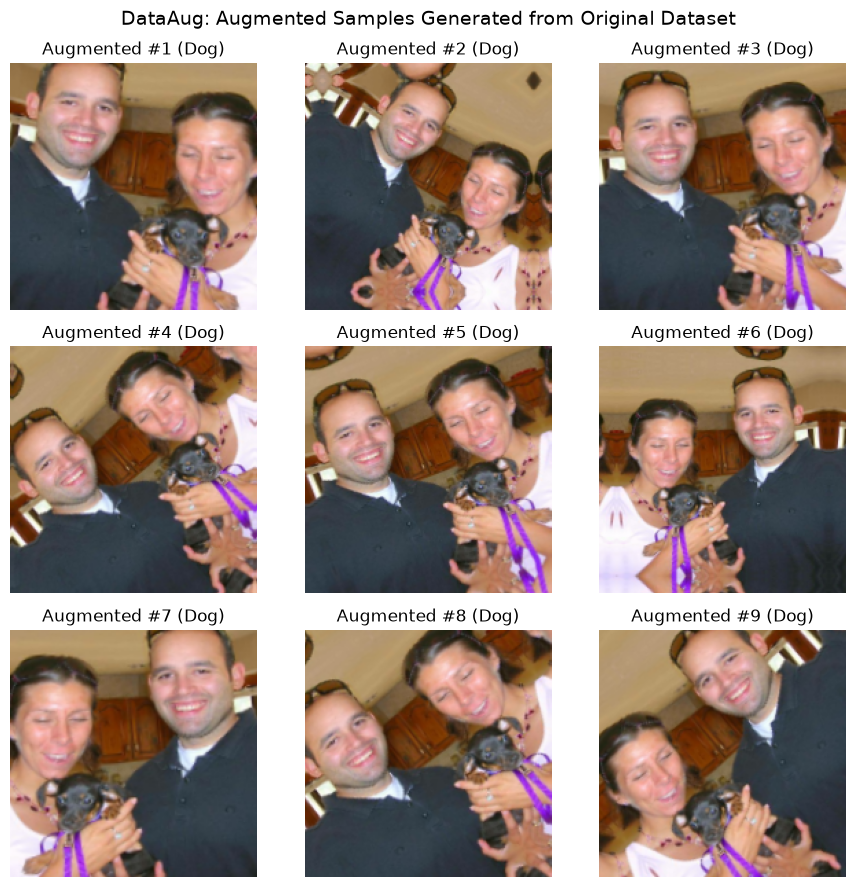

In [3]:
class DataAug:
    """Implements Keras image data augmentation and sample visualization."""

    def __init__(self, flip_mode="horizontal", rotation_factor=0.15, zoom_factor=0.2):
        self.augmentation_layer = keras.Sequential(
            [
                layers.RandomFlip(flip_mode),
                layers.RandomRotation(rotation_factor),
                layers.RandomZoom(zoom_factor),
            ],
            name="data_augmentation",
        )

    def get_layer(self):
        """Returns the sequential augmentation layer for inclusion in a Keras model."""
        return self.augmentation_layer

    def display_augmented_images(self, dataset, num_images=9):
        """Takes one image from the dataset and plots num_images augmented variants."""
        for images, labels in dataset.take(1):
            sample_image = images[0]
            label_name = "Dog" if int(labels[0]) == 1 else "Cat"

            plt.figure(figsize=(9, 9))
            for i in range(num_images):
                ax = plt.subplot(3, 3, i + 1)
                augmented = self.augmentation_layer(tf.expand_dims(sample_image, 0), training=True)
                plt.imshow(augmented[0].numpy().astype("uint8"))
                plt.title(f"Augmented #{i+1} ({label_name})")
                plt.axis("off")
            plt.suptitle("DataAug: Augmented Samples Generated from Original Dataset", fontsize=14)
            plt.tight_layout()
            plt.show()
            break


# Instantiate DataAug and display augmented examples
data_aug = DataAug()
data_aug.display_augmented_images(train_ds, num_images=9)

## 3. Baseline CNN Trained from Scratch (`CatsDogsLimit` Class)
The `CatsDogsLimit` class defines, trains, and evaluates a 4-block convolutional neural network initialized with random weights (`from scratch`) on our limited training dataset (`1,000` images per class). Even with `Dropout(0.5)`, training from scratch on 2,000 images serves as our baseline to observe overfitting and generalization limits without pretrained visual features.

In [4]:
class CatsDogsLimit:
    """Trains and evaluates a cat/dog CNN from scratch using the limited dataset."""

    def __init__(self, input_shape=(180, 180, 3), augmentation_layer=None):
        inputs = keras.Input(shape=input_shape)
        x = augmentation_layer(inputs) if augmentation_layer is not None else inputs
        x = layers.Rescaling(1.0 / 255)(x)

        for filters in [32, 64, 128, 256]:
            x = layers.Conv2D(filters, kernel_size=3, padding="same", activation="relu")(x)
            x = layers.MaxPooling2D(pool_size=2)(x)

        x = layers.Flatten()(x)
        x = layers.Dropout(0.5)(x)
        x = layers.Dense(256, activation="relu")(x)
        outputs = layers.Dense(1, activation="sigmoid")(x)

        self.model = keras.Model(inputs, outputs, name="CatsDogs_Scratch_CNN")
        self.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=1e-3),
            loss="binary_crossentropy",
            metrics=["accuracy"],
        )
        self.history = None

    def train(self, train_data, val_data, epochs=15):
        self.history = self.model.fit(
            train_data,
            validation_data=val_data,
            epochs=epochs,
            verbose=1,
        )
        return self.history

    def evaluate(self, test_data):
        loss, acc = self.model.evaluate(test_data, verbose=0)
        print(f"[CatsDogsLimit - Scratch CNN] Test Loss: {loss:.4f} | Test Accuracy: {acc*100:.2f}%")
        return loss, acc


# Train and evaluate CatsDogsLimit on the limited dataset
limit_classifier = CatsDogsLimit(input_shape=(180, 180, 3), augmentation_layer=data_aug.get_layer())
history_limit = limit_classifier.train(train_ds, val_ds, epochs=15)
limit_test_loss, limit_test_acc = limit_classifier.evaluate(test_ds)

Epoch 1/15


c:\Users\Michel Temgoua\anaconda3\envs\ece-5831-2026\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 29s 428ms/step - accuracy: 0.5090 - loss: 0.6966 - val_accuracy: 0.5320 - val_loss: 0.6876
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 27s 436ms/step - accuracy: 0.5295 - loss: 0.6949 - val_accuracy: 0.5000 - val_loss: 0.6901
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 30s 477ms/step - accuracy: 0.5255 - loss: 0.6907 - val_accuracy: 0.5070 - val_loss: 0.6818
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 38s 609ms/step - accuracy: 0.5400 - loss: 0.6902 - val_accuracy: 0.5370 - val_loss: 0.6947
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 37s 589ms/step - accuracy: 0.5230 - loss: 0.6895 - val_accuracy: 0.5680 - val_loss: 0.6711
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 37s 584ms/step - accuracy: 0.5595 - loss: 0.6852 - val_accuracy: 0.5410 - val_loss: 0.7222
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 37s 580ms/step - accuracy: 0.5630 - loss: 0.6859 - val_accuracy: 0.5990 - val_loss: 0.6553
Epoch 8/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 37s 582ms/step - accuracy: 0.5545 - loss: 0.6806 - val_accuracy: 0.592

## 4. Transfer Learning with Pretrained Backbone (`CatsDogsPre` Class)
The `CatsDogsPre` class leverages **Transfer Learning** by loading a **`VGG16`** convolutional base pretrained on ImageNet (`include_top=False`). We freeze all pretrained convolutional weights (`conv_base.trainable = False`) so generic edge, texture, and object part detectors are preserved, apply `vgg16.preprocess_input`, attach our `DataAug` pipeline, and train only a lightweight custom dense classifier head on the **exact same limited dataset**.

In [5]:
class CatsDogsPre:
    """Trains and evaluates a cat/dog classifier using a frozen pretrained VGG16 backbone."""

    def __init__(self, input_shape=(180, 180, 3), augmentation_layer=None):
        conv_base = keras.applications.VGG16(
            weights="imagenet",
            include_top=False,
            input_shape=input_shape,
        )
        conv_base.trainable = False  # Freeze pretrained convolutional layers

        inputs = keras.Input(shape=input_shape)
        x = augmentation_layer(inputs) if augmentation_layer is not None else inputs
        x = keras.applications.vgg16.preprocess_input(x)
        x = conv_base(x, training=False)
        x = layers.Flatten()(x)
        x = layers.Dense(256, activation="relu")(x)
        x = layers.Dropout(0.5)(x)
        outputs = layers.Dense(1, activation="sigmoid")(x)

        self.model = keras.Model(inputs, outputs, name="CatsDogs_Pretrained_VGG16")
        self.model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=1e-4),
            loss="binary_crossentropy",
            metrics=["accuracy"],
        )
        self.history = None

    def train(self, train_data, val_data, epochs=15):
        self.history = self.model.fit(
            train_data,
            validation_data=val_data,
            epochs=epochs,
            verbose=1,
        )
        return self.history

    def evaluate(self, test_data):
        loss, acc = self.model.evaluate(test_data, verbose=0)
        print(f"[CatsDogsPre - Pretrained VGG16] Test Loss: {loss:.4f} | Test Accuracy: {acc*100:.2f}%")
        return loss, acc


# Train and evaluate CatsDogsPre on the exact same limited dataset
pre_classifier = CatsDogsPre(input_shape=(180, 180, 3), augmentation_layer=data_aug.get_layer())
history_pre = pre_classifier.train(train_ds, val_ds, epochs=15)
pre_test_loss, pre_test_acc = pre_classifier.evaluate(test_ds)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step
Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 208s 3s/step - accuracy: 0.8620 - loss: 1.8869 - val_accuracy: 0.9660 - val_loss: 0.4795
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 245s 4s/step - accuracy: 0.9100 - loss: 1.0724 - val_accuracy: 0.9680 - val_loss: 0.3976
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 245s 4s/step - accuracy: 0.9235 - loss: 0.7237 - val_accuracy: 0.9660 - val_loss: 0.3900
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 244s 4s/step - accuracy: 0.9475 - loss: 0.3888 - val_accuracy: 0.9700 - val_loss: 0.3402
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 247s 4s/step - accuracy: 0.9425 - loss: 0.4137 - val_accuracy: 0.9730 - val_loss: 0.2840
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 268s 4s/step - accuracy: 0.9495 - loss: 0.2471 - val_accuracy: 0.9760 - val_loss: 0.2225
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 244s 4s/step - accuracy: 0.9505 - loss: 0.2949 - val_accuracy: 0.9720 - val_loss: 0.2567
Epoch 8/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 236s 4s/step - accurac

## 5. Performance Comparison: Scratch CNN vs. Pretrained Network (Limited Dataset)
Below we compare training/validation accuracy and loss curves alongside final held-out test set metrics across both models trained on the identical 2,000-image training subset.

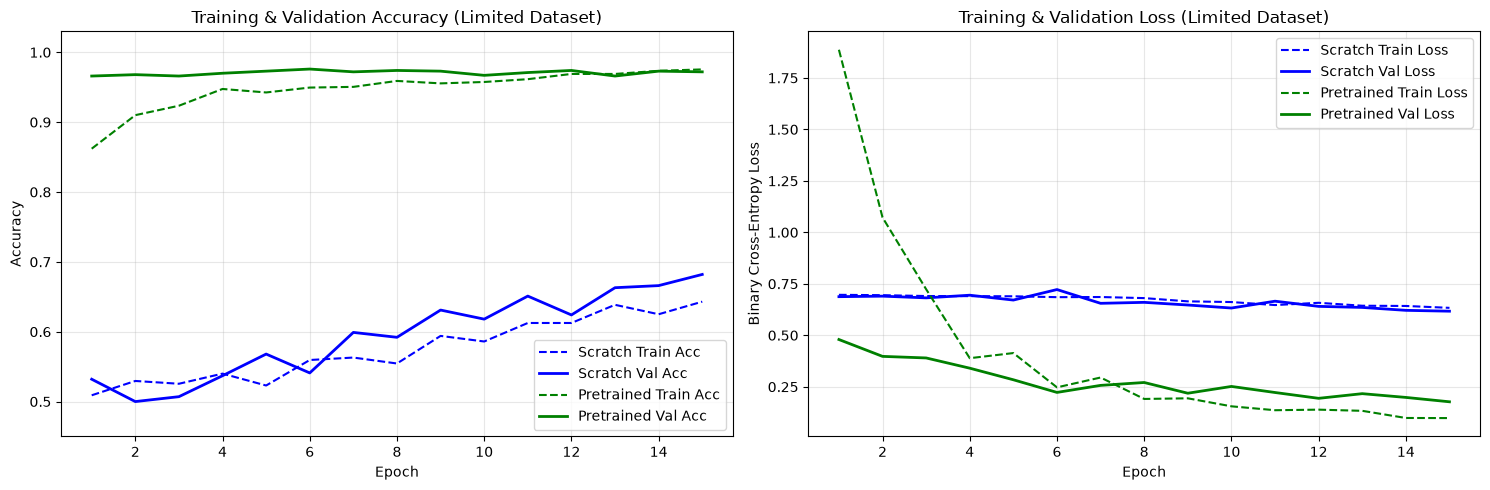

Model                            | Best Val Acc   | Test Acc   | Test Loss
--------------------------------------------------------------------
CatsDogsLimit (From Scratch)     |        68.20% |    65.90% |   0.6226
CatsDogsPre (Pretrained VGG16)   |        97.60% |    97.70% |   0.2062


In [ ]:
def compare_models(hist_scratch, hist_pre, acc_scratch, loss_scratch, acc_pre, loss_pre):
    epochs_range = range(1, len(hist_scratch.history["accuracy"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy comparison
    axes[0].plot(epochs_range, hist_scratch.history["accuracy"], "b--", label="Scratch Train Acc")
    axes[0].plot(epochs_range, hist_scratch.history["val_accuracy"], "b-", linewidth=2, label="Scratch Val Acc")
    axes[0].plot(epochs_range, hist_pre.history["accuracy"], "g--", label="Pretrained Train Acc")
    axes[0].plot(epochs_range, hist_pre.history["val_accuracy"], "g-", linewidth=2, label="Pretrained Val Acc")
    axes[0].set_title("Training & Validation Accuracy (Limited Dataset)")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss comparison
    axes[1].plot(epochs_range, hist_scratch.history["loss"], "b--", label="Scratch Train Loss")
    axes[1].plot(epochs_range, hist_scratch.history["val_loss"], "b-", linewidth=2, label="Scratch Val Loss")
    axes[1].plot(epochs_range, hist_pre.history["loss"], "g--", label="Pretrained Train Loss")
    axes[1].plot(epochs_range, hist_pre.history["val_loss"], "g-", linewidth=2, label="Pretrained Val Loss")
    axes[1].set_title("Training & Validation Loss (Limited Dataset)")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Binary Cross-Entropy Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("=" * 68)
    print(f"{'Model':<32} | {'Best Val Acc':<14} | {'Test Acc':<10} | {'Test Loss':<8}")
    print("-" * 68)
    print(f"{'CatsDogsLimit (From Scratch)':<32} | {max(hist_scratch.history['val_accuracy'])*100:>12.2f}% | {acc_scratch*100:>8.2f}% | {loss_scratch:>8.4f}")
    print(f"{'CatsDogsPre (Pretrained VGG16)':<32} | {max(hist_pre.history['val_accuracy'])*100:>12.2f}% | {acc_pre*100:>8.2f}% | {loss_pre:>8.4f}")
    print("=" * 68)


compare_models(
    history_limit,
    history_pre,
    limit_test_acc,
    limit_test_loss,
    pre_test_acc,
    pre_test_loss,
)

### Key Comparison Observations
1. **Generalization & Test Accuracy:** Using the exact same limited dataset (1,000 training images per class), `CatsDogsLimit` (trained from scratch) reaches **68.20%** best validation accuracy and **65.90%** test accuracy (test loss: **0.6226**). In contrast, `CatsDogsPre` (pretrained VGG16) transfers rich visual representations learned from ImageNet to achieve **97.60%** best validation accuracy and **97.70%** test accuracy (test loss: **0.2062**).
2. **Convergence Speed & Loss:** `CatsDogsPre` rapidly reduces loss within the first few epochs and maintains low training/validation loss throughout all 15 epochs, whereas `CatsDogsLimit` learns much more slowly and plateaus at a substantially higher loss (~0.62–0.70).
3. **Sample Efficiency:** Transfer learning with a pretrained convolutional backbone (`CatsDogsPre`) delivers a **+31.80 percentage-point** test accuracy gain over training a CNN from scratch (`CatsDogsLimit`) on limited data, highlighting its strong sample efficiency when labeled training data is small.